# M10b · Is the feature space already real-centred? (no training)

**Why.** The redesign replaces the linear head (2,050 numbers) by a **real-anchored cosine head** with 2 trained numbers:

p(fake | x) = σ((m₀ − cos(z, c)) / τ),  c = running mean of the L2-normalised features of real training faces (a stored buffer, not trained)

and adds a real-compactness / per-generator margin loss around c. Before building it we check on the existing models whether "distance from the real centroid" already separates real from fake as well as the trained head does.

**Exactness.** For fixed features, the frame-level AUC of this head does not depend on m₀ or τ: it equals the AUC of 1 − cos(z, c). Video scores average over 32 frames, which τ can slightly change; here we average the raw score (τ → ∞ limit). Features of the redesigned model will differ because it is trained for this head; this notebook measures whether the geometry is already there.

**Three scores per model, all from the same features z (1024-d, L2-normalised):**

| score | trained numbers | what it uses |
|---|---|---|
| linear head (reference) | 2,050 | the trained head |
| real-centroid 1 − cos(z, c) | 0 (plus 2 for the head form) | mean of real training features only |
| mean-difference w·z, w = normalise(μ_fake − μ_real) | 0 | means of real and fake training features |

If real-centroid ≈ linear head → the cosine head is supported. If only mean-difference ≈ linear head → the separating direction exists but is not real-centred → fallback: single-direction head w·z + b (1,025 numbers).

Also measured: how close each generator's fakes sit to c (the per-generator margins the new loss would act on), and how the trained head direction aligns with −c and with the mean-difference direction.

| Section | What it does | Run time |
|---|---|---|
| 1–2 | settings, model, helpers | ~2 min |
| 3 | load crops (FF++ train subset + test, DFD, UADFV) | ~3–8 min |
| 4 | features for every model (cached to disk, resumable) | ~1 min (FF++) + ~3 min (DFD) per model |
| 5 | AUC tables, margins, head alignment, histograms | ~1 min |
| 6 | decision and summary | seconds |

## 1. Setup

### 1.1 Settings

Paths as in M8b/M9b. Nothing is written outside `runs/m10b/`.

In [1]:
# 1.1 Settings
from pathlib import Path

DATA_ROOT = Path("/nlsasfs/home/isea/isea64/GBLA-Deepfake Detection")
RUNS_ROOT = DATA_ROOT / "runs"
FACES_FF = DATA_ROOT / "faces"
FACES_DFD = DATA_ROOT / "faces_dfd"
FACES_UADFV = DATA_ROOT / "faces_uadfv"
FF_INDEX = DATA_ROOT / "index" / "ffpp_c23.csv"
DFD_INDEX = DATA_ROOT / "index" / "dfd_c23.csv"
UADFV_INDEX = DATA_ROOT / "index" / "uadfv.csv"
M10B_DIR = RUNS_ROOT / "m10b"

ARCH, PRETRAINED = "ViT-L-14", "openai"
SEED = 0
EPOCH = 10
EVAL_BATCH = 256
LOAD_THREADS = 16

TRAIN_REALS = None          # None = all 23,040 real training crops for the centroid
TRAIN_FAKES_PER_GEN = 5760  # fake training crops per generator for the mean-difference score
RUN_DFD = True
RUN_UADFV = True
TOL_AUC = 1.0               # decision tolerance (AUC points) vs the linear head

M1_DIR = RUNS_ROOT / "m1" / f"lnclip_{ARCH}_train-DF-F2F-FS-NT_seed{SEED}"


def m4_run(tag):
    return RUNS_ROOT / "m4" / f"gbla_lam{tag}_{ARCH}_seed{SEED}"


MODELS = {
    "m1": ("LNCLIP-DF repro (M1, epoch 10)", "state", M1_DIR / f"epoch_{EPOCH:02d}.pt"),
    "lam_inf": ("pooled, λ=∞ (M4)", "gbla", m4_run("inf") / f"epoch_{EPOCH:02d}.pt"),
    "lam_0.01": ("GBLA λ=0.01 (ours)", "gbla", m4_run("0.01") / f"epoch_{EPOCH:02d}.pt"),
}
REFERENCE = {"m1": {"seen": 97.60, "FSh": 88.19}, "lam_inf": {"seen": 96.41, "FSh": 90.53},
             "lam_0.01": {"seen": 95.55, "FSh": 92.91}}
TRAIN_GENERATORS = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures"]

(M10B_DIR / "features").mkdir(parents=True, exist_ok=True)
for k, (_, _, path) in MODELS.items():
    assert path.exists(), f"checkpoint missing: {k} -> {path}"
print("models:", list(MODELS), "   results ->", M10B_DIR)

models: ['m1', 'lam_inf', 'lam_0.01']    results -> /nlsasfs/home/isea/isea64/GBLA-Deepfake Detection/runs/m10b


In [2]:
# 1.2 Imports and environment
import json, math, random, time
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import open_clip
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from PIL import Image
from tqdm.auto import tqdm

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda"
CLIP_MEAN = (0.48145466, 0.4578275, 0.40821073)
CLIP_STD = (0.26862954, 0.26130258, 0.27577711)
display(pd.Series({"torch": torch.__version__, "open_clip": open_clip.__version__,
                   "GPU": torch.cuda.get_device_name(0)}, name="value").to_frame())

/nlsasfs/home/isea/isea64/venv_jupyter/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,value
torch,2.6.0+cu124
open_clip,3.3.0
GPU,NVIDIA A100-SXM4-40GB


## 2. Model

### 2.1 Detector and checkpoints

Same detector as every earlier milestone.

In [3]:
# 2.1 Detector (as in M1/M4/M8b/M9b) and parameter report
class Detector(nn.Module):
    def __init__(self):
        super().__init__()
        encoder = open_clip.create_model(ARCH, pretrained=PRETRAINED, force_quick_gelu=True).visual
        encoder.proj = None
        self.encoder = encoder
        self.head = nn.Linear(encoder.transformer.width, 2)

    def forward(self, x):
        f = F.normalize(self.encoder(x).float(), dim=-1)
        return self.head(f), f


torch.manual_seed(SEED)
model = Detector().to(DEVICE).eval()
model.requires_grad_(False)
for m in model.encoder.modules():
    if isinstance(m, nn.LayerNorm):
        m.requires_grad_(True)
model.head.requires_grad_(True)

PARAMS = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
PARAM_NAMES = [n for n, _ in PARAMS]
P = sum(p.numel() for _, p in PARAMS)
TOTAL = sum(p.numel() for p in model.parameters())
param_report = {"total": TOTAL, "trainable (deployed)": P, "frozen": TOTAL - P,
                "trainable %": round(100 * P / TOTAL, 4)}
display(pd.Series(param_report, name="parameters").to_frame())
assert P == 104_450, P

THETA0 = torch.cat([p.detach().reshape(-1) for _, p in PARAMS]).float().cpu()   # pretrained LayerNorms + untrained head


@torch.no_grad()
def set_flat(theta):
    theta = theta.to(DEVICE).float()
    assert theta.numel() == P, (theta.numel(), P)
    offset = 0
    for _, p in PARAMS:
        n = p.numel()
        p.copy_(theta[offset:offset + n].view_as(p).to(p.dtype))
        offset += n


def load(path):
    return torch.load(path, map_location="cpu", weights_only=False)


def load_theta(kind, path):
    obj = load(path)
    if kind == "state":
        state = obj.get("trainable", obj)
        return torch.cat([state[n].reshape(-1).float() for n in PARAM_NAMES])
    if kind == "gbla":
        return obj.get("gbla", obj)["theta_s"].float()
    raise ValueError(kind)


THETAS = {k: load_theta(kind, path) for k, (_, kind, path) in MODELS.items()}
print({k: f"{v.numel():,}" for k, v in THETAS.items()})

,parameters
total,3.031818e+08
trainable (deployed),1.044500e+05
frozen,3.030774e+08
trainable %,3.450000e-02


{'m1': '104,450', 'lam_inf': '104,450', 'lam_0.01': '104,450'}


In [4]:
# 2.2 Image loading, prediction and AUC helpers
MEAN_GPU = torch.tensor(CLIP_MEAN, device=DEVICE).view(1, 3, 1, 1)
STD_GPU = torch.tensor(CLIP_STD, device=DEVICE).view(1, 3, 1, 1)


def read_rgb(path):
    with Image.open(path) as im:
        return np.asarray(im.convert("RGB"))


def load_images(paths, desc):
    images = np.empty((len(paths), 224, 224, 3), dtype=np.uint8)

    def fill(i):
        images[i] = read_rgb(paths[i])

    with ThreadPoolExecutor(LOAD_THREADS) as pool:
        list(tqdm(pool.map(fill, range(len(paths)), chunksize=64), total=len(paths), desc=desc))
    return images


@torch.no_grad()
def run_model(theta, images, desc="predict", want_features=False):
    """Fake probability per crop (linear head); optionally the L2-normalised CLS features (float16)."""
    set_flat(theta)
    probs, feats = [], []
    for s in tqdm(range(0, len(images), EVAL_BATCH), desc=desc, leave=False):
        x = torch.from_numpy(images[s:s + EVAL_BATCH]).to(DEVICE, non_blocking=True)
        x = (x.permute(0, 3, 1, 2).float() / 255 - MEAN_GPU) / STD_GPU
        with torch.autocast("cuda", dtype=torch.bfloat16):
            logits, f = model(x)
        probs.append(logits.float().softmax(1)[:, 1].cpu())
        if want_features:
            feats.append(F.normalize(f.float(), dim=-1).half().cpu())
    probs = torch.cat(probs).numpy()
    return (probs, torch.cat(feats).numpy()) if want_features else probs


def auc(labels, scores):
    labels = np.asarray(labels)
    ranks = pd.Series(np.asarray(scores)).rank().values
    n_pos = labels.sum()
    n_neg = len(labels) - n_pos
    if n_pos == 0 or n_neg == 0:
        return float("nan")
    return float((ranks[labels == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))


SEEN = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures"]
SHORT = {"Deepfakes": "DF", "Face2Face": "F2F", "FaceSwap": "FS", "NeuralTextures": "NT", "FaceShifter": "FSh"}


def ff_video_aucs(test_df, scores):
    """FF++ test video AUC (%): seen combined, each generator, FaceShifter. Each generator vs the same real test videos."""
    df = test_df.assign(score=scores)
    vid = df.groupby(["generator", "video_id"], as_index=False).agg(label=("label", "first"), score=("score", "mean"))
    out = {}
    for name, gens in [("seen", SEEN)] + [(SHORT[g], [g]) for g in SEEN + ["FaceShifter"]]:
        sub = vid[vid.generator.isin(["original", *gens])]
        out[name] = 100 * auc(sub.label, sub.score)
    return out


def video_auc(index_df, scores):
    """Video AUC (%) for DFD / UADFV: video score = mean frame score."""
    vid = index_df.assign(score=scores).groupby("video_id", as_index=False).agg(label=("label", "first"), score=("score", "mean"))
    return 100 * auc(vid.label, vid.score)

## 3. Crops

FF++ train: all real training crops (for the centroid) and 5,760 fake crops per training generator (for the mean-difference score); FF++ test; DFD; UADFV. A set is read only if a model still needs its features.

In [5]:
# 3. Crops into RAM
ff = pd.read_csv(FF_INDEX, dtype={"video_id": str, "target_id": str, "source_id": str}, keep_default_na=False)
tr = ff[ff.split == "train"]
train_real = tr[tr.generator == "original"]
if TRAIN_REALS is not None:
    train_real = train_real.sample(TRAIN_REALS, random_state=SEED)
train_fake = pd.concat([tr[tr.generator == g].sample(TRAIN_FAKES_PER_GEN, random_state=SEED) for g in TRAIN_GENERATORS])
train_df = pd.concat([train_real, train_fake]).reset_index(drop=True)
ff_test = ff[ff.split == "test"].reset_index(drop=True)
display(pd.DataFrame({"train (centroid / means)": train_df.generator.value_counts(), "test": ff_test.generator.value_counts()}))

SETS = {"train": (train_df, FACES_FF), "test": (ff_test, FACES_FF)}
if RUN_DFD:
    SETS["dfd"] = (pd.read_csv(DFD_INDEX), FACES_DFD)
if RUN_UADFV:
    SETS["uadfv"] = (pd.read_csv(UADFV_INDEX, dtype={"video_id": str, "pair_id": str}), FACES_UADFV)
IMAGES = {}


def images_of(name):
    """Crops are loaded only when a model still needs features for this set."""
    if name not in IMAGES:
        df, root = SETS[name]
        IMAGES[name] = load_images([str(root / p) for p in df.path], desc=f"{name} crops")
    return IMAGES[name]

,train (centroid / means),test
generator,,
Deepfakes,5760.0,4480
Face2Face,5760.0,4480
FaceShifter,NaN,4480
FaceSwap,5760.0,4480
NeuralTextures,5760.0,4480
original,23040.0,4480


## 4. Features

L2-normalised CLS features (float16) and linear-head probabilities for every model and set, saved to `runs/m10b/features/` so an interrupted session continues. The linear head must reproduce the known FF++ results (tolerance 0.3).

In [6]:
# 4. Features and linear-head probabilities (cached in runs/m10b/features)
FEATS, PROBS = {}, {}
for k in MODELS:
    for name, (df, _) in SETS.items():
        f_path = M10B_DIR / "features" / f"{k}_{name}_z.npy"
        p_path = M10B_DIR / "features" / f"{k}_{name}_p.npy"
        if f_path.exists() and p_path.exists():
            z, p = np.load(f_path), np.load(p_path)
            if len(z) == len(df):
                FEATS[k, name], PROBS[k, name] = z, p
                continue
        t0 = time.time()
        p, z = run_model(THETAS[k], images_of(name), desc=f"{k} {name}", want_features=True)
        np.save(f_path, z); np.save(p_path, p)
        FEATS[k, name], PROBS[k, name] = z, p
        print(f"{k} {name}: {len(z):,} features in {time.time() - t0:.0f} s")
IMAGES.clear()

# load check: the linear head must reproduce the known FF++ results
check = pd.DataFrame({k: {**{f"{m}": ff_video_aucs(ff_test, PROBS[k, "test"])[m] for m in ("seen", "FSh")},
                          **{f"expected {m}": REFERENCE[k][m] for m in ("seen", "FSh")}} for k in MODELS}).T
check["ok"] = ((check.seen - check["expected seen"]).abs() < 0.3) & ((check.FSh - check["expected FSh"]).abs() < 0.3)
display(check)
assert check.ok.all(), "a checkpoint does not reproduce its FF++ results"

train crops: 100%|██████████| 46080/46080 [00:33<00:00, 1372.51it/s]
                                                           

m1 train: 46,080 features in 116 s


test crops: 100%|██████████| 26880/26880 [00:18<00:00, 1421.31it/s]
                                                          

m1 test: 26,880 features in 61 s


dfd crops: 100%|██████████| 109454/109454 [01:05<00:00, 1681.67it/s]
                                                         

m1 dfd: 109,454 features in 237 s


... (7 outputs left out)

lam_0.01 test: 26,880 features in 41 s


lam_0.01 dfd: 109,454 features in 169 s


lam_0.01 uadfv: 3,136 features in 5 s


,seen,FSh,expected seen,expected FSh,ok
m1,97.598214,88.193878,97.60,88.19,True
lam_inf,96.405612,90.530612,96.41,90.53,True
lam_0.01,95.552296,92.913265,95.55,92.91,True


## 5. Results

### 5.1 Video AUC: linear head vs real-centroid vs mean-difference

Video score = mean frame score. FF++ columns: seen combined, each training generator, FaceShifter (unseen). `Δ` rows = score − linear head.

In [7]:
# 5.1 Scores and AUC tables
def unit(v):
    return v / np.linalg.norm(v)


CENTROID, MEANDIFF, HEADDIR = {}, {}, {}
for k in MODELS:
    z = FEATS[k, "train"].astype(np.float32)
    real = (train_df.label == 0).values
    CENTROID[k] = unit(z[real].mean(0))
    MEANDIFF[k] = unit(z[~real].mean(0) - z[real].mean(0))
    set_flat(THETAS[k])
    W = model.head.weight.detach().float().cpu().numpy()
    HEADDIR[k] = unit(W[1] - W[0])


def scores(k, name, kind):
    z = FEATS[k, name].astype(np.float32)
    if kind == "linear head":
        return PROBS[k, name]
    if kind == "real-centroid":
        return 1 - z @ CENTROID[k]
    if kind == "mean-difference":
        return z @ MEANDIFF[k]
    raise ValueError(kind)


KINDS = ["linear head", "real-centroid", "mean-difference"]
rows = []
for k in MODELS:
    for kind in KINDS:
        row = {"model": MODELS[k][0], "score": kind, **ff_video_aucs(ff_test, scores(k, "test", kind))}
        if RUN_DFD:
            row["DFD"] = video_auc(SETS["dfd"][0], scores(k, "dfd", kind))
        if RUN_UADFV:
            row["UADFV"] = video_auc(SETS["uadfv"][0], scores(k, "uadfv", kind))
        rows.append(row)
auc_table = pd.DataFrame(rows).set_index(["model", "score"])
delta = auc_table.groupby(level=0, group_keys=False).apply(lambda t: t - t.xs("linear head", level=1).iloc[0])
display(auc_table.round(2))
print("difference to the linear head (AUC points):")
display(delta.drop(index="linear head", level=1).round(2))
auc_table.to_csv(M10B_DIR / "auc_by_score.csv")

seen     DF    F2F     FS  \
model                          score                                         
LNCLIP-DF repro (M1, epoch 10) linear head      97.60  99.22  98.09  99.20   
                               real-centroid    97.28  99.23  97.91  98.72   
                               mean-difference  97.73  99.23  98.35  99.19   
pooled, λ=∞ (M4)               linear head      96.41  99.72  98.66  99.34   
                               real-centroid    95.77  99.77  98.28  99.13   
                               mean-difference  96.51  99.77  98.70  99.42   
GBLA λ=0.01 (ours)             linear head      95.55  99.43  98.55  99.17   
                               real-centroid    94.56  99.57  97.98  98.89   
                               mean-difference  95.28  99.51  98.38  99.24   

                                                   NT    FSh    DFD  UADFV  
model                          score                                        
LNCLIP-DF repro (M1, epoch 10) linear head      93.88  88.19  95.88  99.25  
                               real-centroid    93.26  85.46  94.74  99.63  
                               mean-difference  94.14  87.80  96.20  99.50  
pooled, λ=∞ (M4)               linear head      87.90  90.53  96.05  99.38  
                               real-centroid    85.92  86.99  95.27  99.79  
                               mean-difference  88.13  89.79  96.26  99.42  
GBLA λ=0.01 (ours)             linear head      85.06  92.91  96.71  99.63  
                               real-centroid    81.80  90.64  95.72  99.83  
                               mean-difference  83.97  92.63  96.69  99.79

difference to the linear head (AUC points):


seen    DF   F2F    FS    NT  \
model                          score                                           
LNCLIP-DF repro (M1, epoch 10) real-centroid   -0.32  0.01 -0.18 -0.47 -0.62   
                               mean-difference  0.13  0.01  0.26 -0.01  0.27   
pooled, λ=∞ (M4)               real-centroid   -0.63  0.05 -0.39 -0.21 -1.97   
                               mean-difference  0.10  0.05  0.04  0.08  0.23   
GBLA λ=0.01 (ours)             real-centroid   -0.99  0.13 -0.56 -0.28 -3.27   
                               mean-difference -0.28  0.07 -0.16  0.08 -1.09   

                                                 FSh   DFD  UADFV  
model                          score                               
LNCLIP-DF repro (M1, epoch 10) real-centroid   -2.73 -1.15   0.37  
                               mean-difference -0.40  0.32   0.25  
pooled, λ=∞ (M4)               real-centroid   -3.54 -0.78   0.42  
                               mean-difference -0.74  0.21   0.04  
GBLA λ=0.01 (ours)             real-centroid   -2.27 -0.99   0.21  
                               mean-difference -0.28 -0.02   0.17

### 5.2 Geometry: margins per generator and head alignment

`cos to c`: cosine of each crop's feature to the real centroid (median and 5th / 95th percentiles) for real crops and for each generator, on FF++ test (DFD/UADFV real and fake as well). The per-generator margin term of the new loss acts exactly on these numbers: a generator whose fakes sit as close to c as the reals is the one that needs the most weight.

`alignment`: cosine between the trained head direction (w₁ − w₀) and −c (real-centroid direction) and the mean-difference direction.

model            lam_0.01  lam_inf     m1
set       group                          
DFD       fake      0.009    0.004  0.003
          real      0.309    0.275  0.257
FF++ test DF       -0.011   -0.037 -0.039
          F2F       0.023    0.017 -0.008
          FS        0.019   -0.013 -0.033
          FSh       0.134    0.158  0.172
          NT        0.206    0.166  0.073
          real      0.381    0.351  0.342
UADFV     fake     -0.022   -0.025 -0.040
          real      0.291    0.250  0.281

,"cos(head dir, −c)","cos(head dir, mean-diff)","cos(mean-diff, −c)"
"LNCLIP-DF repro (M1, epoch 10)",0.611,0.799,0.806
"pooled, λ=∞ (M4)",0.613,0.819,0.787
GBLA λ=0.01 (ours),0.663,0.850,0.797


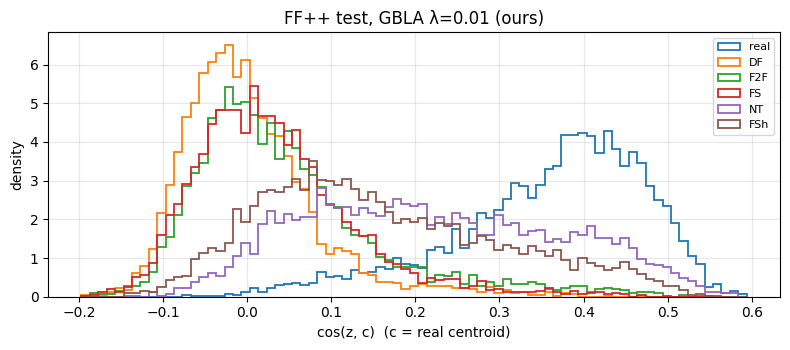

In [8]:
# 5.2 Margins and alignment
def pct(x):
    return {"median": float(np.median(x)), "p5": float(np.percentile(x, 5)), "p95": float(np.percentile(x, 95))}


rows = []
for k in MODELS:
    cos_test = FEATS[k, "test"].astype(np.float32) @ CENTROID[k]
    for g in ["original", *TRAIN_GENERATORS, "FaceShifter"]:
        rows.append({"model": k, "set": "FF++ test", "group": SHORT.get(g, "real"), **pct(cos_test[(ff_test.generator == g).values])})
    for name in [n for n in ("dfd", "uadfv") if n in SETS]:
        df = SETS[name][0]
        c = FEATS[k, name].astype(np.float32) @ CENTROID[k]
        for lab, grp in [(0, "real"), (1, "fake")]:
            rows.append({"model": k, "set": name.upper(), "group": grp, **pct(c[(df.label == lab).values])})
margins = pd.DataFrame(rows)
display(margins.pivot_table(index=["set", "group"], columns="model", values="median").round(3))
margins.to_csv(M10B_DIR / "cos_to_centroid.csv", index=False)

align = pd.DataFrame({MODELS[k][0]: {"cos(head dir, −c)": float(HEADDIR[k] @ -CENTROID[k]),
                                     "cos(head dir, mean-diff)": float(HEADDIR[k] @ MEANDIFF[k]),
                                     "cos(mean-diff, −c)": float(MEANDIFF[k] @ -CENTROID[k])} for k in MODELS}).T
display(align.round(3))
align.to_csv(M10B_DIR / "head_alignment.csv")

k = "lam_0.01"
cos_test = FEATS[k, "test"].astype(np.float32) @ CENTROID[k]
fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.linspace(cos_test.min(), cos_test.max(), 80)
for g in ["original", *TRAIN_GENERATORS, "FaceShifter"]:
    ax.hist(cos_test[(ff_test.generator == g).values], bins=bins, histtype="step", density=True, lw=1.3,
            label=SHORT.get(g, "real"))
ax.set_xlabel("cos(z, c)  (c = real centroid)"); ax.set_ylabel("density"); ax.set_title(f"FF++ test, {MODELS[k][0]}")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(M10B_DIR / "cos_hist.png", dpi=150); plt.show()

## 6. Decision

For GBLA λ = 0.01, on FaceShifter (unseen generator) and DFD (unseen dataset):

- **cosine head supported** if the real-centroid score is within `TOL_AUC` (1.0) of the linear head on both;
- **fallback: 1-direction head** (w·z + b, 1,025 numbers) if only the mean-difference score is within tolerance;
- **keep the linear head** if neither is.

In [9]:
# 6. Decision and summary
k = MODELS["lam_0.01"][0]
cols = ["FSh"] + (["DFD"] if RUN_DFD else [])
gap = {kind: {c: float(auc_table.loc[(k, kind), c] - auc_table.loc[(k, "linear head"), c]) for c in cols}
       for kind in ["real-centroid", "mean-difference"]}
centroid_ok = all(v >= -TOL_AUC for v in gap["real-centroid"].values())
meandiff_ok = all(v >= -TOL_AUC for v in gap["mean-difference"].values())
verdict = ("cosine head supported" if centroid_ok else
           "fallback: 1-direction head" if meandiff_ok else "keep the linear head")
print("gaps to the linear head (AUC points):", json.dumps(gap, indent=1))
print("VERDICT:", verdict)

summary = {
    "question": "does 1 - cos(z, real centroid) separate real and fake as well as the trained linear head",
    "auc_by_score": auc_table.round(3).reset_index().to_dict("records"),
    "head_alignment": align.round(4).to_dict("index"),
    "cos_to_centroid_median": margins.round(4).to_dict("records"),
    "gap_lam_0.01": gap, "tolerance": TOL_AUC, "verdict": verdict,
    "note": "features come from models trained with the linear head; the redesigned model is trained for the cosine head",
}
(M10B_DIR / "summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False, default=str))

gaps to the linear head (AUC points): {
 "real-centroid": {
  "FSh": -2.2704081632653015,
  "DFD": -0.9922922480703704
 },
 "mean-difference": {
  "FSh": -0.28061224489796643,
  "DFD": -0.020472593662105965
 }
}
VERDICT: fallback: 1-direction head


7767